In [ ]:
#Electric Vehicle Population Data

#https://catalog.data.gov/dataset/electric-vehicle-population-data

#This dataset shows the Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs) 
#that are currently registered through Washington State Department of Licensing (DOL).

In [32]:
#-------------------------------
# 1. Import Required Libraries
#-------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from numpy.linalg import matrix_rank, det

plt.style.use("seaborn-v0_8")

In [34]:
#-------------------------------
# 2. Load Dataset (Mac Path)
#-------------------------------

file_path = "/Users/adityavardhan/Downloads/Electric_Vehicle_Population_Data.csv"

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully")
print("Shape:", df.shape)
df.head()

Dataset Loaded Successfully
Shape: (276828, 16)


,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EBXJ,Yakima,Yakima,WA,98902.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,14.0,131356970,POINT (-120.51904 46.59783),PACIFICORP,5.307700e+10
1,1N4BZ0CP2G,King,Kent,WA,98030.0,2016,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,84.0,33.0,211702123,POINT (-122.19975 47.37483),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
2,1C4JJXP64P,Snohomish,Marysville,WA,98271.0,2023,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,21.0,38.0,238694900,POINT (-122.17138 48.10433),PUGET SOUND ENERGY INC,5.306194e+10
3,WA1E2AFY0S,Snohomish,Bothell,WA,98012.0,2025,AUDI,Q5 E,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,28.0,1.0,278444183,POINT (-122.20105 47.84423),PUGET SOUND ENERGY INC,5.306105e+10
4,1N4AZ0CPXG,King,Seattle,WA,98125.0,2016,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,84.0,46.0,252437846,POINT (-122.30253 47.72656),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10


In [36]:
#-------------------------------
# 3. Data Cleaning & Selection
#-------------------------------

df.columns = df.columns.str.strip()

# Convert numeric safely
df['Electric Range'] = pd.to_numeric(df['Electric Range'], errors='coerce')
df['Model Year'] = pd.to_numeric(df['Model Year'], errors='coerce')

# Select variables
df_selected = df[['Electric Range', 'Model Year', 'County']].copy()

# Remove missing
df_selected = df_selected.dropna()

# Remove zero ranges
df_selected = df_selected[df_selected['Electric Range'] > 0]

print("Cleaned Dataset Shape:", df_selected.shape)

Cleaned Dataset Shape: (101320, 3)


In [12]:
#-------------------------------
# 4. Select Key Variables for Analysis
#-------------------------------

# Clean column names
df.columns = df.columns.str.strip()

# Print columns once to confirm
print("Available Columns:\n", df.columns)

# Convert numeric columns safely
df['Electric Range'] = pd.to_numeric(df['Electric Range'], errors='coerce')
df['Model Year'] = pd.to_numeric(df['Model Year'], errors='coerce')

# Select variables
continuous_cols = ['Electric Range']
numeric_extra = ['Model Year']
discrete_col = 'County'   # categorical variable

df_selected = df[continuous_cols + numeric_extra + [discrete_col]].copy()

# Remove missing values
df_selected = df_selected.dropna()

# Remove zero range vehicles (improves modelling)
df_selected = df_selected[df_selected['Electric Range'] > 0]

print("Cleaned Dataset Shape:", df_selected.shape)
df_selected.head()

Available Columns:
 Index(['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year',
       'Make', 'Model', 'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range',
       'Legislative District', 'DOL Vehicle ID', 'Vehicle Location',
       'Electric Utility', '2020 Census Tract'],
      dtype='object')
Cleaned Dataset Shape: (101320, 3)


,Electric Range,Model Year,County
0,215.0,2018,Yakima
1,84.0,2016,King
2,21.0,2023,Snohomish
3,28.0,2025,Snohomish
4,84.0,2016,King


In [38]:
#-------------------------------
# 4. Vector Operations
#-------------------------------

v_range = df_selected['Electric Range'].to_numpy()
v_year = df_selected['Model Year'].to_numpy()

dot_product = np.dot(v_range, v_year)

norm_range = np.linalg.norm(v_range)
norm_year = np.linalg.norm(v_year)

cosine_similarity = dot_product / (norm_range * norm_year)

print("Dot Product:", dot_product)
print("Norm (Range):", norm_range)
print("Norm (Year):", norm_year)
print("Cosine Similarity:", cosine_similarity)

Dot Product: 22039978371.0
Norm (Range): 46197.866303542636
Norm (Year): 642845.2007909836
Cosine Similarity: 0.7421348741925873


In [40]:
#-------------------------------
# 5. Matrix Operations
#-------------------------------

X = df_selected[['Electric Range', 'Model Year']].to_numpy()

XtX = X.T @ X

rank_X = matrix_rank(X)
determinant = det(XtX)

print("X^T X:\n", XtX)
print("Rank of X:", rank_X)
print("Determinant of X^T X:", determinant)

X^T X:
 [[2.13424285e+09 2.20399784e+10]
 [2.20399784e+10 4.13249952e+11]]
Rank of X: 2
Determinant of X^T X: 3.962151095221086e+20


In [18]:
#-------------------------------
# 7. Descriptive Statistics
#-------------------------------

summary_stats = df_selected[['Electric Range', 'Model Year']].describe()

variance = df_selected[['Electric Range', 'Model Year']].var()
skewness = df_selected[['Electric Range', 'Model Year']].skew()
kurtosis = df_selected[['Electric Range', 'Model Year']].kurt()

print(summary_stats)
print("\nVariance:\n", variance)
print("\nSkewness:\n", skewness)
print("\nKurtosis:\n", kurtosis)

       Electric Range     Model Year
count   101320.000000  101320.000000
mean       107.755438    2019.566443
std         97.227761       3.546359
min          1.000000    1999.000000
25%         30.000000    2017.000000
50%         47.000000    2019.000000
75%        215.000000    2023.000000
max        337.000000    2026.000000

Variance:
 Electric Range    9453.237547
Model Year          12.576661
dtype: float64

Skewness:
 Electric Range    0.72080
Model Year       -0.16434
dtype: float64

Kurtosis:
 Electric Range   -1.071274
Model Year       -0.651728
dtype: float64


In [42]:
#-------------------------------
# 6. Descriptive Statistics
#-------------------------------

summary = df_selected[['Electric Range', 'Model Year']].describe()
variance = df_selected[['Electric Range', 'Model Year']].var()
skewness = df_selected[['Electric Range', 'Model Year']].skew()
kurtosis = df_selected[['Electric Range', 'Model Year']].kurt()

print(summary)
print("\nVariance:\n", variance)
print("\nSkewness:\n", skewness)
print("\nKurtosis:\n", kurtosis)

       Electric Range     Model Year
count   101320.000000  101320.000000
mean       107.755438    2019.566443
std         97.227761       3.546359
min          1.000000    1999.000000
25%         30.000000    2017.000000
50%         47.000000    2019.000000
75%        215.000000    2023.000000
max        337.000000    2026.000000

Variance:
 Electric Range    9453.237547
Model Year          12.576661
dtype: float64

Skewness:
 Electric Range    0.72080
Model Year       -0.16434
dtype: float64

Kurtosis:
 Electric Range   -1.071274
Model Year       -0.651728
dtype: float64


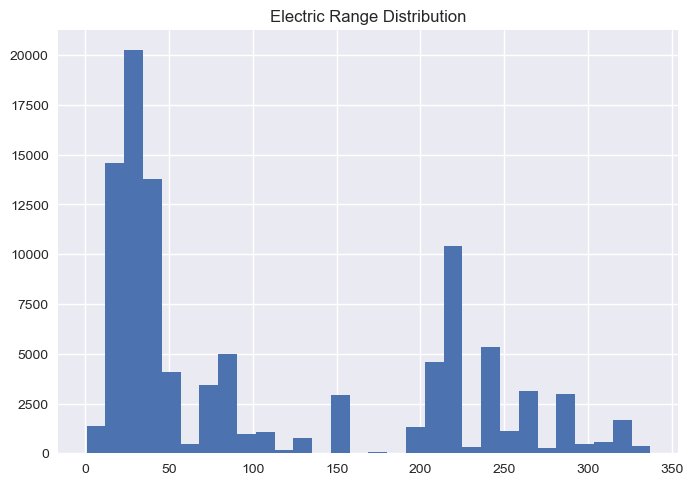

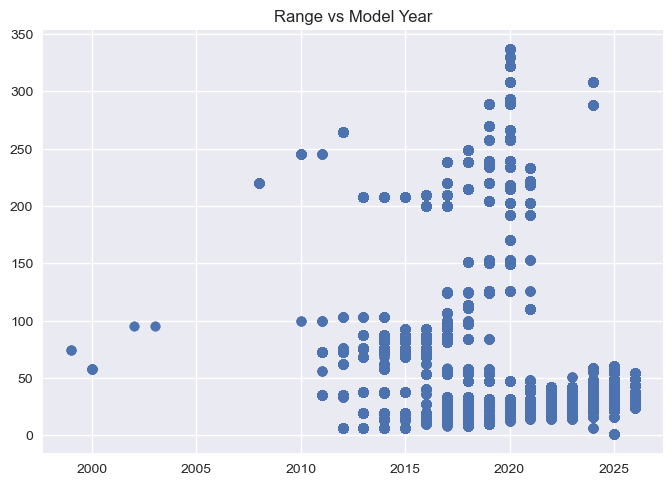

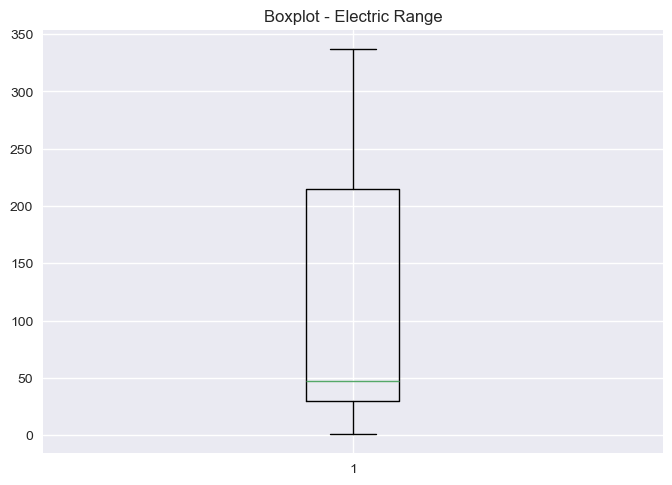

In [44]:
#-------------------------------
# 7. Exploratory Data Analysis
#-------------------------------

plt.figure()
plt.hist(df_selected['Electric Range'], bins=30)
plt.title("Electric Range Distribution")
plt.show()

plt.figure()
plt.scatter(df_selected['Model Year'], df_selected['Electric Range'])
plt.title("Range vs Model Year")
plt.show()

plt.figure()
plt.boxplot(df_selected['Electric Range'])
plt.title("Boxplot - Electric Range")
plt.show()

In [46]:
#-------------------------------
# 8. Discrete Random Variable (County Count)
#-------------------------------

county_counts = df_selected['County'].value_counts()

pmf_empirical = county_counts / county_counts.sum()

print("Empirical PMF (First 5):\n", pmf_empirical.head())

Empirical PMF (First 5):
 County
King         0.461646
Snohomish    0.105685
Pierce       0.084426
Clark        0.067311
Thurston     0.040229
Name: count, dtype: float64


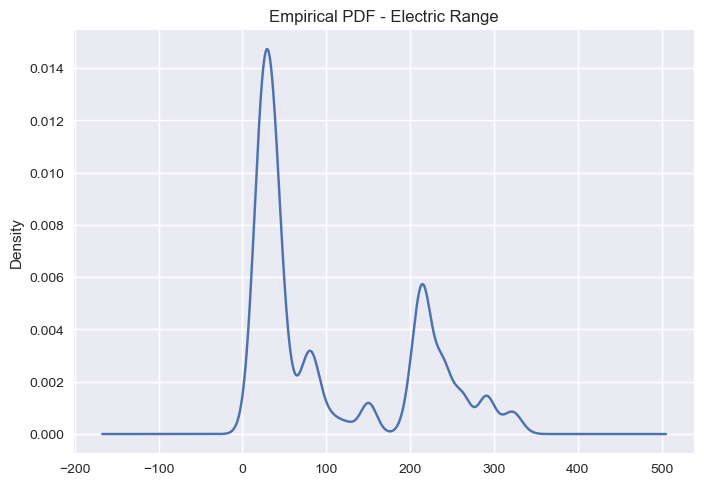

In [48]:
#-------------------------------
# 9. Continuous Random Variable (Electric Range)
#-------------------------------

continuous_var = df_selected['Electric Range']

plt.figure()
continuous_var.plot(kind='kde')
plt.title("Empirical PDF - Electric Range")
plt.show()

Estimated Lambda: 4605.454545454545


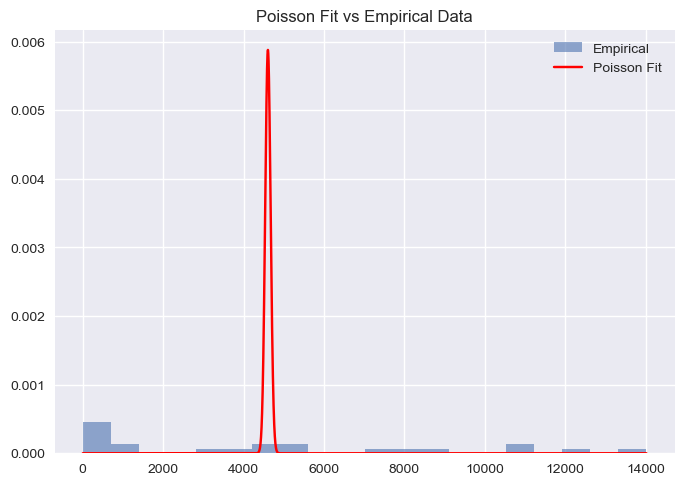

In [50]:
#-------------------------------
# 10. Poisson Distribution Fit
#-------------------------------

# Vehicle count per year (better discrete modelling choice)
year_counts = df_selected['Model Year'].value_counts()

lambda_est = year_counts.mean()

print("Estimated Lambda:", lambda_est)

# Compare empirical vs theoretical Poisson
x_vals = np.arange(year_counts.min(), year_counts.max()+1)
poisson_pmf = stats.poisson.pmf(x_vals, lambda_est)

plt.figure()
plt.hist(year_counts, bins=20, density=True, alpha=0.6, label="Empirical")
plt.plot(x_vals, poisson_pmf, 'r-', label="Poisson Fit")
plt.legend()
plt.title("Poisson Fit vs Empirical Data")
plt.show()

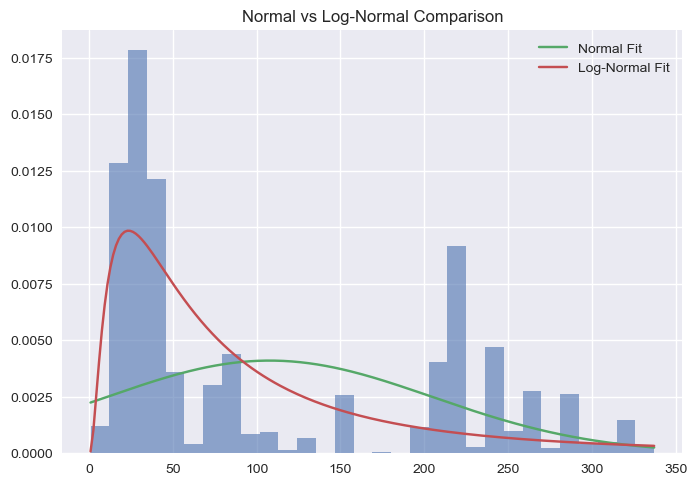

Normal Mean: 107.75543821555468
Normal Std Dev: 97.22728138741917
Lognormal Shape: 1.018920093131838


In [52]:
#-------------------------------
# 11. Normal vs Log-Normal Fit
#-------------------------------

# Normal Fit
mu, sigma = stats.norm.fit(continuous_var)

# Log-Normal Fit
shape, loc, scale = stats.lognorm.fit(continuous_var, floc=0)

x = np.linspace(continuous_var.min(), continuous_var.max(), 200)

normal_pdf = stats.norm.pdf(x, mu, sigma)
lognormal_pdf = stats.lognorm.pdf(x, shape, loc, scale)

plt.figure()
plt.hist(continuous_var, bins=30, density=True, alpha=0.6)
plt.plot(x, normal_pdf, label="Normal Fit")
plt.plot(x, lognormal_pdf, label="Log-Normal Fit")
plt.legend()
plt.title("Normal vs Log-Normal Comparison")
plt.show()

print("Normal Mean:", mu)
print("Normal Std Dev:", sigma)
print("Lognormal Shape:", shape)

In [54]:
#-------------------------------
# 12. Hypothesis Testing
#-------------------------------

# H0: Mean Electric Range = 150
# H1: Mean Electric Range ≠ 150

t_stat, p_value = stats.ttest_1samp(continuous_var, 150)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0 at 5% significance level")
else:
    print("Fail to reject H0")

T-statistic: -138.30188975313598
P-value: 0.0
Reject H0 at 5% significance level


In [56]:
#-------------------------------
# 13. Correlation Matrix
#-------------------------------

correlation_matrix = df_selected[['Electric Range', 'Model Year']].corr()

print(correlation_matrix)

                Electric Range  Model Year
Electric Range        1.000000   -0.263509
Model Year           -0.263509    1.000000
